# SI 30-Frame Modality Effect Comparison

This notebook compares the modality effect for the 30-frame SI experiments currently available in artifacts.

Focus:

- training curves from history.json
- testing comparison from summary.json / metrics.json
- literal hand vs hand_body deltas for each model

Current modalities:

- hand
- hand_body


In [1]:
from pathlib import Path

SCENARIO = "si"
FRAME_SAMPLE_COUNT = 30
MODALITIES = ("hand", "hand_body")
MODELS_TO_COMPARE = ("cnn1d", "lstm", "transformer", "gcn")

ARTIFACTS_DIR = Path("artifacts")
EXPERIMENTS_DIR = ARTIFACTS_DIR / "experiments" / SCENARIO

METRIC_COLUMNS = ("accuracy", "f1_score", "loss")
PLOT_FIGSIZE = (14, 9)
MODALITY_COLORS = {"hand": "#4C78A8", "hand_body": "#F58518"}


In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 140)


In [3]:
def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def find_matching_runs(model_name: str, modality: str) -> list[Path]:
    run_root = EXPERIMENTS_DIR / model_name / modality
    if not run_root.exists():
        return []

    matches = []
    for run_dir in sorted(path for path in run_root.iterdir() if path.is_dir()):
        config_path = run_dir / "config.json"
        summary_path = run_dir / "summary.json"
        history_path = run_dir / "history.json"
        if not (config_path.exists() and summary_path.exists() and history_path.exists()):
            continue

        config = read_json(config_path)
        if (
            config.get("scenario") == SCENARIO
            and config.get("model") == model_name
            and config.get("modality") == modality
            and int(config.get("frame_sample_count", -1)) == FRAME_SAMPLE_COUNT
        ):
            matches.append(run_dir)
    return matches


def latest_matching_run(model_name: str, modality: str) -> Path:
    matches = find_matching_runs(model_name, modality)
    if not matches:
        raise FileNotFoundError(
            f"No {SCENARIO.upper()} {FRAME_SAMPLE_COUNT}-frame run found for {model_name}/{modality}"
        )
    return matches[-1]


def load_run_bundle(model_name: str, modality: str) -> dict:
    run_dir = latest_matching_run(model_name, modality)
    config = read_json(run_dir / "config.json")
    summary = read_json(run_dir / "summary.json")
    history = read_json(run_dir / "history.json")
    metrics = read_json(run_dir / "metrics.json") if (run_dir / "metrics.json").exists() else summary.get("metrics", {})
    return {
        "model": model_name,
        "modality": modality,
        "run_dir": run_dir,
        "config": config,
        "summary": summary,
        "history": history,
        "metrics": metrics,
    }


def load_all_runs() -> dict[tuple[str, str], dict]:
    bundles = {}
    for model_name in MODELS_TO_COMPARE:
        for modality in MODALITIES:
            bundles[(model_name, modality)] = load_run_bundle(model_name, modality)
    return bundles


def make_summary_table(run_bundles: dict[tuple[str, str], dict]) -> pd.DataFrame:
    rows = []
    for (model_name, modality), bundle in run_bundles.items():
        config = bundle["config"]
        summary = bundle["summary"]
        metrics = bundle["metrics"]
        run_id = bundle["run_dir"].name
        rows.append(
            {
                "display_label": f"{model_name} {modality}",
                "display_color": MODALITY_COLORS.get(modality, "#666666"),
                "scenario": config.get("scenario", summary.get("scenario")),
                "model": model_name,
                "modality": modality,
                "run_id": run_id,
                "frames": config.get("frame_sample_count"),
                "input_shape": tuple(config.get("input_shape", summary.get("input_shape", []))),
                "parameters": summary.get("parameter_count"),
                "train_size": summary.get("train_size"),
                "test_size": summary.get("test_size"),
                "accuracy": metrics.get("accuracy"),
                "f1_score": metrics.get("f1_score"),
                "loss": metrics.get("loss"),
                "run_dir": str(bundle["run_dir"]),
            }
        )
    return pd.DataFrame(rows).sort_values(["model", "modality"]).reset_index(drop=True)


run_bundles = load_all_runs()
summary_df = make_summary_table(run_bundles)

display(
    summary_df.drop(columns=["display_color"]).style.format(
        {
            "accuracy": "{:.4f}",
            "f1_score": "{:.4f}",
            "loss": "{:.4f}",
            "parameters": "{:,.0f}",
            "train_size": "{:,.0f}",
            "test_size": "{:,.0f}",
        }
    )
)


,display_label,scenario,model,modality,run_id,frames,input_shape,parameters,train_size,test_size,accuracy,f1_score,loss,run_dir
0,cnn1d hand,si,cnn1d,hand,20260504T163204Z,30,"(30, 210)","498,859","50,458","32,941",0.1816,0.1680,4.8966,artifacts/experiments/si/cnn1d/hand/20260504T163204Z
1,cnn1d hand_body,si,cnn1d,hand_body,20260526T011219Z,30,"(30, 375)","562,219","50,458","32,941",0.2306,0.2189,4.2174,artifacts/experiments/si/cnn1d/hand_body/20260526T011219Z
2,gcn hand,si,gcn,hand,20260504T163204Z,30,"(30, 210)","381,427","50,458","32,941",0.1624,0.1521,4.7866,artifacts/experiments/si/gcn/hand/20260504T163204Z
3,gcn hand_body,si,gcn,hand_body,20260525T174227Z,30,"(30, 375)","389,149","50,458","32,941",0.2611,0.2519,3.7966,artifacts/experiments/si/gcn/hand_body/20260525T174227Z
4,lstm hand,si,lstm,hand,20260504T163205Z,30,"(30, 210)","880,299","50,458","32,941",0.3639,0.3551,3.1282,artifacts/experiments/si/lstm/hand/20260504T163205Z
5,lstm hand_body,si,lstm,hand_body,20260526T022042Z,30,"(30, 375)","1,049,259","50,458","32,941",0.3264,0.3160,3.2313,artifacts/experiments/si/lstm/hand_body/20260526T022042Z
6,transformer hand,si,transformer,hand,20260504T163204Z,30,"(30, 210)","1,039,787","50,458","32,941",0.5153,0.5114,2.4122,artifacts/experiments/si/transformer/hand/20260504T163204Z
7,transformer hand_body,si,transformer,hand_body,20260525T174227Z,30,"(30, 375)","1,060,907","50,458","32,941",0.5372,0.5339,2.0523,artifacts/experiments/si/transformer/hand_body/20260525T174227Z


## Run And Parameter Overview

The selected runs are the latest artifact folders matching scenario SI, frame_sample_count 30, and each model/modality pair. Parameter count is included because hand_body increases the input width from hand-only features.


,display_label,scenario,model,modality,run_id,frames,input_shape,parameters,run_dir
0,cnn1d hand,si,cnn1d,hand,20260504T163204Z,30,"(30, 210)","498,859",artifacts/experiments/si/cnn1d/hand/20260504T163204Z
1,cnn1d hand_body,si,cnn1d,hand_body,20260526T011219Z,30,"(30, 375)","562,219",artifacts/experiments/si/cnn1d/hand_body/20260526T011219Z
2,gcn hand,si,gcn,hand,20260504T163204Z,30,"(30, 210)","381,427",artifacts/experiments/si/gcn/hand/20260504T163204Z
3,gcn hand_body,si,gcn,hand_body,20260525T174227Z,30,"(30, 375)","389,149",artifacts/experiments/si/gcn/hand_body/20260525T174227Z
4,lstm hand,si,lstm,hand,20260504T163205Z,30,"(30, 210)","880,299",artifacts/experiments/si/lstm/hand/20260504T163205Z
5,lstm hand_body,si,lstm,hand_body,20260526T022042Z,30,"(30, 375)","1,049,259",artifacts/experiments/si/lstm/hand_body/20260526T022042Z
6,transformer hand,si,transformer,hand,20260504T163204Z,30,"(30, 210)","1,039,787",artifacts/experiments/si/transformer/hand/20260504T163204Z
7,transformer hand_body,si,transformer,hand_body,20260525T174227Z,30,"(30, 375)","1,060,907",artifacts/experiments/si/transformer/hand_body/20260525T174227Z


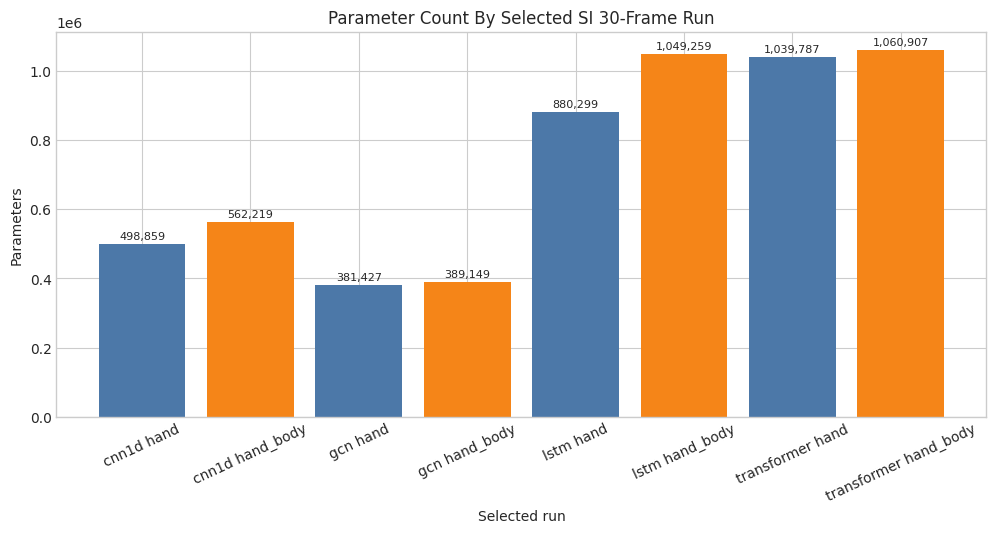

In [4]:
run_overview = summary_df[[
    "display_label",
    "scenario",
    "model",
    "modality",
    "run_id",
    "frames",
    "input_shape",
    "parameters",
    "run_dir",
]].copy()
display(run_overview.style.format({"parameters": "{:,.0f}"}))

parameter_plot = summary_df.sort_values(["model", "modality"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(parameter_plot["display_label"], parameter_plot["parameters"], color=parameter_plot["display_color"])
ax.set_title("Parameter Count By Selected SI 30-Frame Run")
ax.set_ylabel("Parameters")
ax.set_xlabel("Selected run")
ax.tick_params(axis="x", rotation=25)
for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)
plt.show()


## Testing Comparison

This section uses the saved test metrics from each selected run. Positive deltas mean hand_body improved over hand; negative deltas mean hand stayed ahead.


In [5]:
def make_metric_pivot(summary_df: pd.DataFrame, metric_name: str) -> pd.DataFrame:
    pivot = summary_df.pivot(index="model", columns="modality", values=metric_name).reindex(MODELS_TO_COMPARE)
    if set(MODALITIES).issubset(pivot.columns):
        pivot["hand_body_minus_hand"] = pivot["hand_body"] - pivot["hand"]
        if metric_name != "loss":
            pivot["relative_delta_%"] = 100 * pivot["hand_body_minus_hand"] / pivot["hand"]
    return pivot


metric_pivots = {metric_name: make_metric_pivot(summary_df, metric_name) for metric_name in METRIC_COLUMNS}

print("Accuracy")
display(metric_pivots["accuracy"].style.format("{:.4f}"))

print("Macro F1 / Keras F1")
display(metric_pivots["f1_score"].style.format("{:.4f}"))

print("Loss")
display(metric_pivots["loss"].style.format("{:.4f}"))


Accuracy


modality,hand,hand_body,hand_body_minus_hand,relative_delta_%
model,,,,
cnn1d,0.1816,0.2306,0.0490,26.9855
lstm,0.3639,0.3264,-0.0376,-10.3186
transformer,0.5153,0.5372,0.0219,4.2597
gcn,0.1624,0.2611,0.0987,60.7477


Macro F1 / Keras F1


modality,hand,hand_body,hand_body_minus_hand,relative_delta_%
model,,,,
cnn1d,0.1680,0.2189,0.0509,30.3042
lstm,0.3551,0.3160,-0.0390,-10.9938
transformer,0.5114,0.5339,0.0224,4.3813
gcn,0.1521,0.2519,0.0998,65.6258


Loss


modality,hand,hand_body,hand_body_minus_hand
model,,,
cnn1d,4.8966,4.2174,-0.6792
lstm,3.1282,3.2313,0.1031
transformer,2.4122,2.0523,-0.3599
gcn,4.7866,3.7966,-0.9900


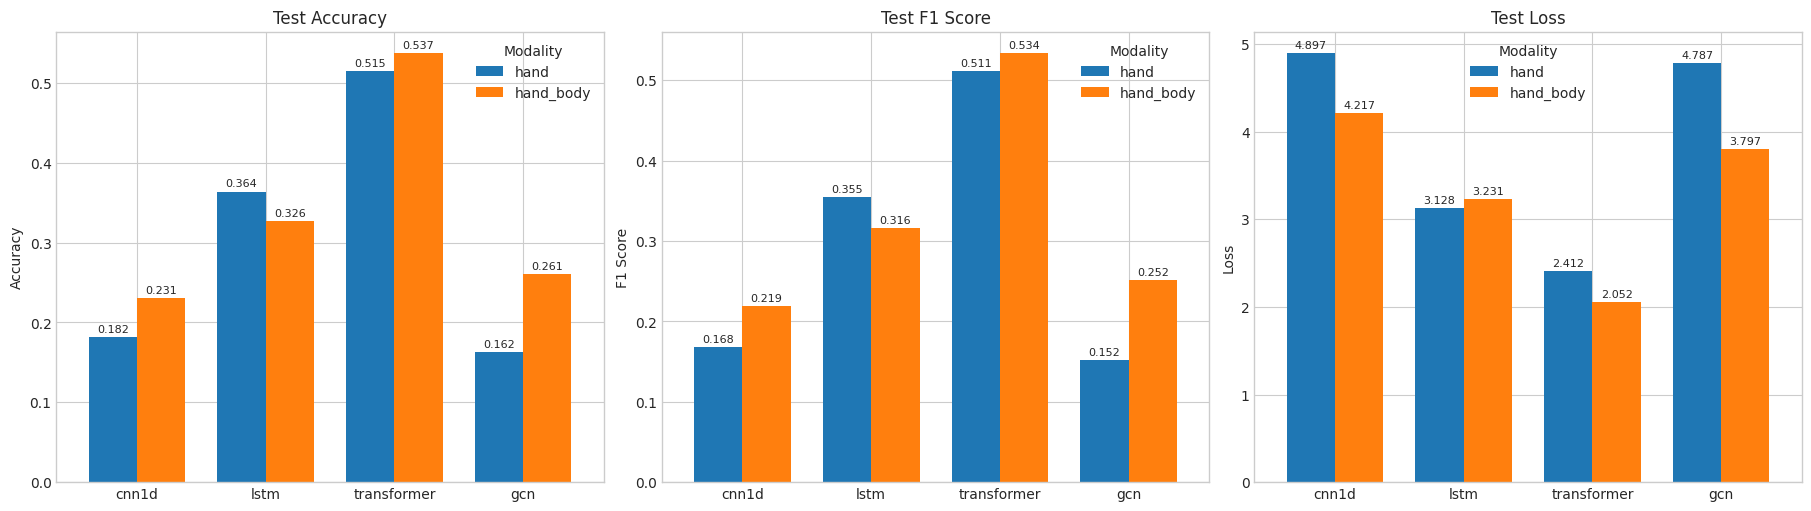

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
plot_specs = [
    ("accuracy", "Test Accuracy", "higher"),
    ("f1_score", "Test F1 Score", "higher"),
    ("loss", "Test Loss", "lower"),
]

for ax, (metric_name, title, direction) in zip(axes, plot_specs):
    pivot = summary_df.pivot(index="model", columns="modality", values=metric_name).reindex(MODELS_TO_COMPARE)
    pivot.plot(kind="bar", ax=ax, width=0.75)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(metric_name.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Modality")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

plt.show()


In [7]:
delta_df = summary_df.pivot(index="model", columns="modality", values=["accuracy", "f1_score", "loss"]).reindex(MODELS_TO_COMPARE)
delta_rows = []
for model_name in MODELS_TO_COMPARE:
    row = {"model": model_name}
    for metric_name in METRIC_COLUMNS:
        hand = delta_df.loc[model_name, (metric_name, "hand")]
        hand_body = delta_df.loc[model_name, (metric_name, "hand_body")]
        row[f"{metric_name}_hand"] = hand
        row[f"{metric_name}_hand_body"] = hand_body
        row[f"{metric_name}_delta"] = hand_body - hand
    delta_rows.append(row)

delta_comparison_df = pd.DataFrame(delta_rows)
display(delta_comparison_df.style.format({column: "{:.4f}" for column in delta_comparison_df.columns if column != "model"}))


,model,accuracy_hand,accuracy_hand_body,accuracy_delta,f1_score_hand,f1_score_hand_body,f1_score_delta,loss_hand,loss_hand_body,loss_delta
0,cnn1d,0.1816,0.2306,0.0490,0.1680,0.2189,0.0509,4.8966,4.2174,-0.6792
1,lstm,0.3639,0.3264,-0.0376,0.3551,0.3160,-0.0390,3.1282,3.2313,0.1031
2,transformer,0.5153,0.5372,0.0219,0.5114,0.5339,0.0224,2.4122,2.0523,-0.3599
3,gcn,0.1624,0.2611,0.0987,0.1521,0.2519,0.0998,4.7866,3.7966,-0.9900


## Training Curves

Solid lines show training metrics; dashed lines show validation metrics. Each subplot compares hand and hand_body for the same model.


In [8]:
def history_frame(bundle: dict) -> pd.DataFrame:
    history = bundle["history"]
    epochs = range(1, max(len(values) for values in history.values() if isinstance(values, list)) + 1)
    frame = pd.DataFrame({"epoch": list(epochs)})
    for key, values in history.items():
        if isinstance(values, list):
            frame[key] = values
    frame["model"] = bundle["model"]
    frame["modality"] = bundle["modality"]
    return frame


history_df = pd.concat([history_frame(bundle) for bundle in run_bundles.values()], ignore_index=True)
display(history_df.groupby(["model", "modality"]).agg(epochs=("epoch", "max")).reset_index())


,model,modality,epochs
0,cnn1d,hand,100
1,cnn1d,hand_body,100
2,gcn,hand,100
3,gcn,hand_body,100
4,lstm,hand,100
5,lstm,hand_body,100
6,transformer,hand,100
7,transformer,hand_body,100


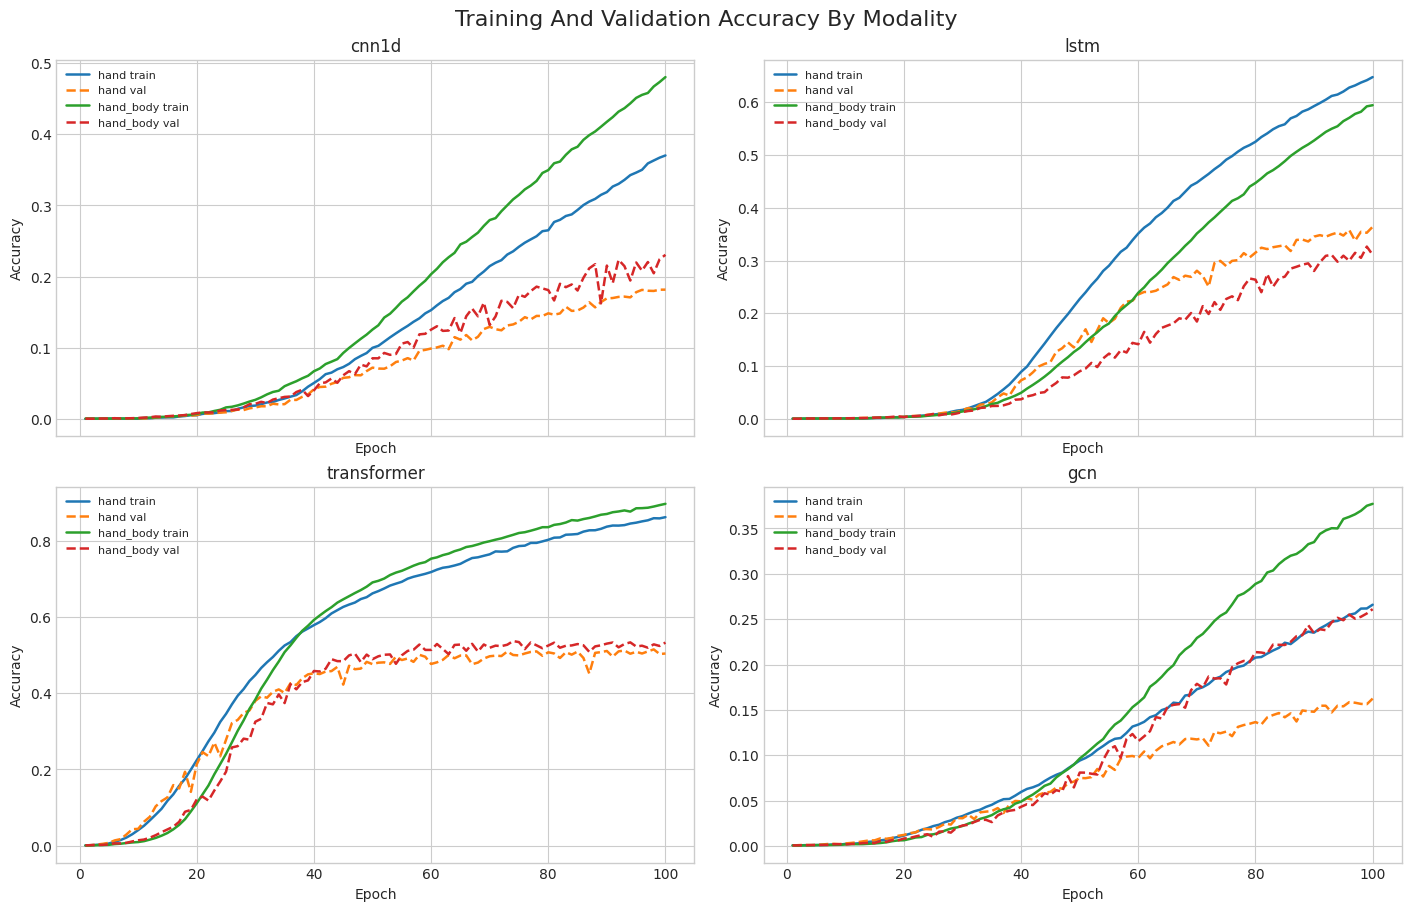

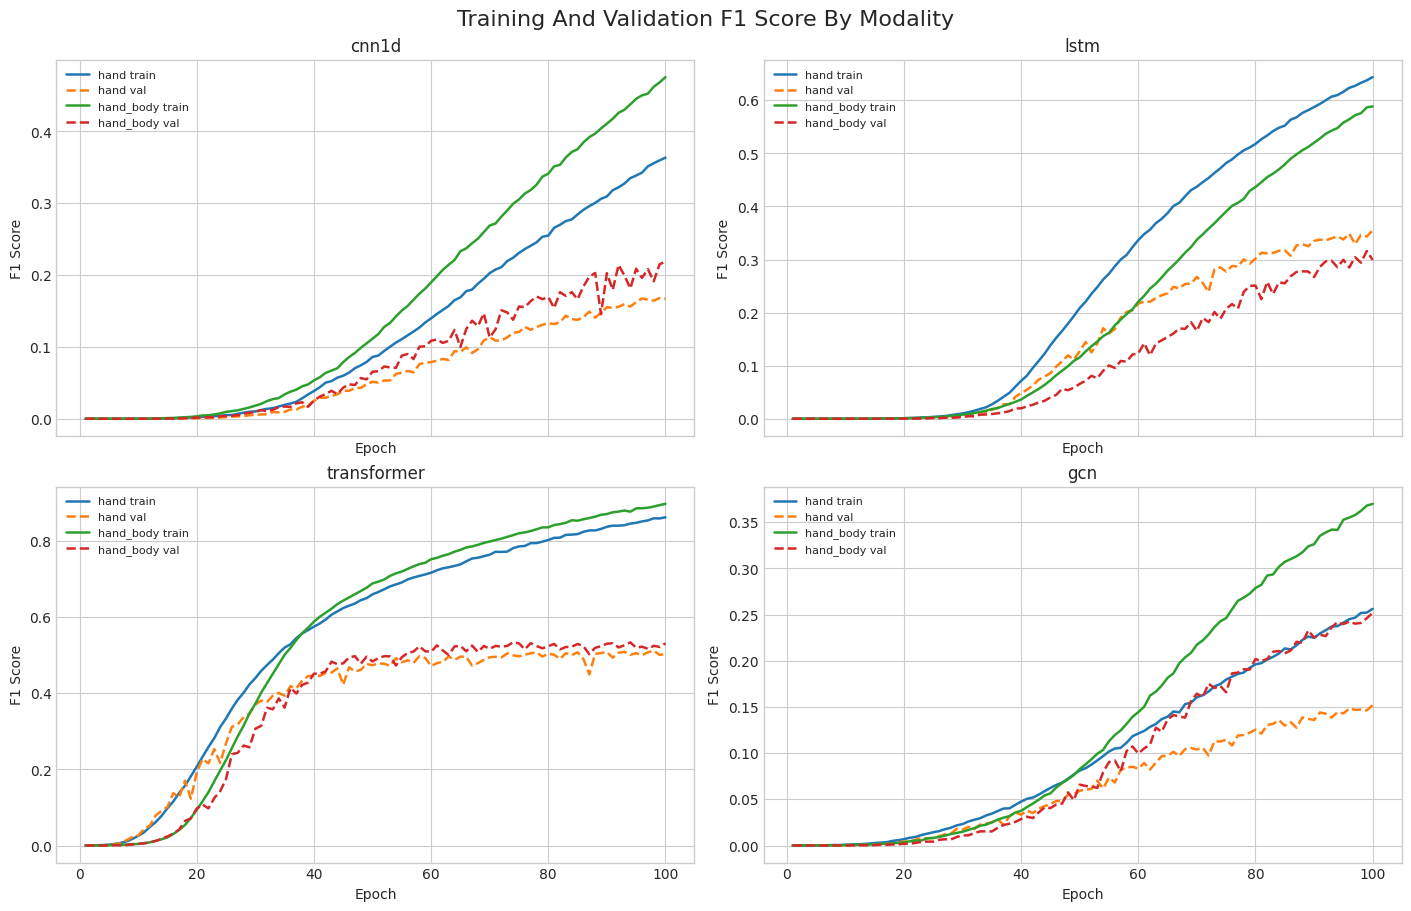

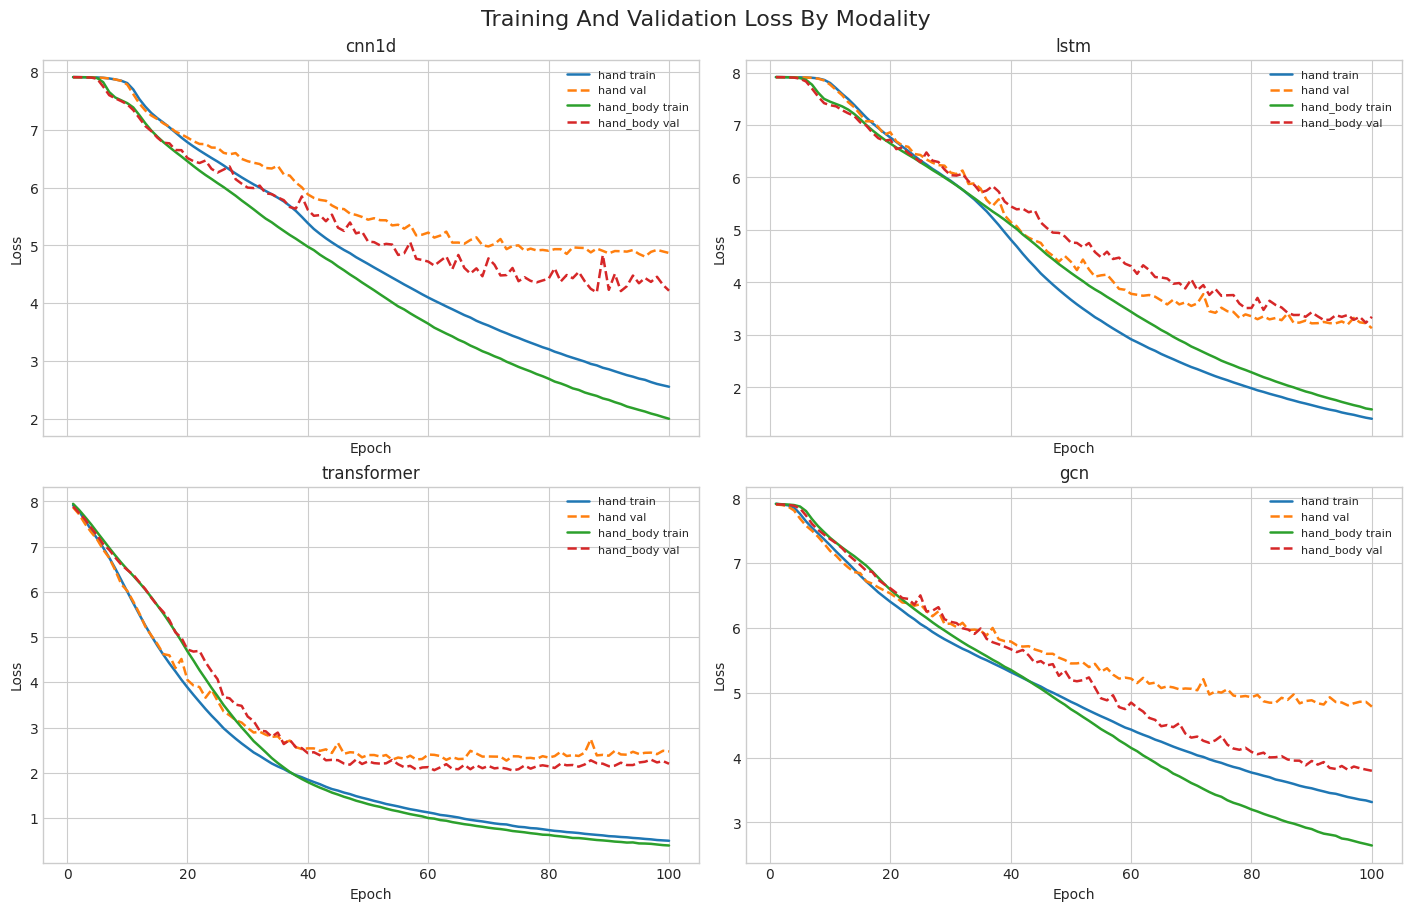

In [9]:
def plot_training_metric(metric_name: str, title: str, ylabel: str):
    fig, axes = plt.subplots(2, 2, figsize=PLOT_FIGSIZE, sharex=True, constrained_layout=True)
    axes = axes.flatten()

    for ax, model_name in zip(axes, MODELS_TO_COMPARE):
        model_history = history_df.loc[history_df["model"] == model_name]
        for modality in MODALITIES:
            data = model_history.loc[model_history["modality"] == modality]
            ax.plot(data["epoch"], data[metric_name], label=f"{modality} train", linewidth=1.8)
            val_metric = f"val_{metric_name}"
            if val_metric in data:
                ax.plot(data["epoch"], data[val_metric], label=f"{modality} val", linewidth=1.8, linestyle="--")

        ax.set_title(model_name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)

    fig.suptitle(title, fontsize=16)
    plt.show()


plot_training_metric("accuracy", "Training And Validation Accuracy By Modality", "Accuracy")
plot_training_metric("f1_score", "Training And Validation F1 Score By Modality", "F1 Score")
plot_training_metric("loss", "Training And Validation Loss By Modality", "Loss")


In [10]:
def best_history_value(frame: pd.DataFrame, metric_name: str, mode: str) -> float:
    if metric_name not in frame:
        return np.nan
    values = frame[metric_name].dropna()
    if values.empty:
        return np.nan
    return values.min() if mode == "min" else values.max()


training_rows = []
for (model_name, modality), bundle in run_bundles.items():
    frame = history_frame(bundle)
    training_rows.append(
        {
            "model": model_name,
            "modality": modality,
            "final_train_accuracy": frame["accuracy"].iloc[-1],
            "final_val_accuracy": frame["val_accuracy"].iloc[-1],
            "best_val_accuracy": best_history_value(frame, "val_accuracy", "max"),
            "final_train_f1": frame["f1_score"].iloc[-1],
            "final_val_f1": frame["val_f1_score"].iloc[-1],
            "best_val_f1": best_history_value(frame, "val_f1_score", "max"),
            "final_train_loss": frame["loss"].iloc[-1],
            "final_val_loss": frame["val_loss"].iloc[-1],
            "best_val_loss": best_history_value(frame, "val_loss", "min"),
        }
    )

training_summary_df = pd.DataFrame(training_rows).sort_values(["model", "modality"]).reset_index(drop=True)
display(training_summary_df.style.format({column: "{:.4f}" for column in training_summary_df.columns if column not in {"model", "modality"}}))


,model,modality,final_train_accuracy,final_val_accuracy,best_val_accuracy,final_train_f1,final_val_f1,best_val_f1,final_train_loss,final_val_loss,best_val_loss
0,cnn1d,hand,0.3702,0.1817,0.1817,0.3635,0.1672,0.1680,2.5566,4.8702,4.8080
1,cnn1d,hand_body,0.4803,0.2306,0.2306,0.4756,0.2189,0.2189,2.0021,4.2174,4.1879
2,gcn,hand,0.2660,0.1624,0.1624,0.2562,0.1521,0.1521,3.3134,4.7866,4.7866
3,gcn,hand_body,0.3772,0.2611,0.2611,0.3699,0.2519,0.2519,2.6434,3.7966,3.7966
4,lstm,hand,0.6475,0.3639,0.3639,0.6437,0.3551,0.3551,1.4024,3.1282,3.1282
5,lstm,hand_body,0.5942,0.3107,0.3264,0.5885,0.2993,0.3160,1.5804,3.3451,3.2313
6,transformer,hand,0.8625,0.5044,0.5153,0.8620,0.5024,0.5114,0.4976,2.4722,2.2690
7,transformer,hand_body,0.8975,0.5332,0.5372,0.8973,0.5309,0.5339,0.3926,2.1996,2.0523


## Artifact-Driven Analysis

Run the next cell after loading the tables above. It writes a compact interpretation based on the discovered artifacts, so the notes stay aligned if new 30-frame modality runs are added later.


In [11]:
def format_pct(value: float) -> str:
    return f"{100 * value:.2f}%"


def model_list(models: list[str]) -> str:
    return ", ".join(models) if models else "none"


best_accuracy = summary_df.sort_values("accuracy", ascending=False).iloc[0]
best_f1 = summary_df.sort_values("f1_score", ascending=False).iloc[0]
best_loss = summary_df.sort_values("loss", ascending=True).iloc[0]

accuracy_delta = metric_pivots["accuracy"]["hand_body_minus_hand"].dropna()
f1_delta = metric_pivots["f1_score"]["hand_body_minus_hand"].dropna()
loss_delta = metric_pivots["loss"]["hand_body_minus_hand"].dropna()

accuracy_helped = accuracy_delta[accuracy_delta > 0].index.tolist()
accuracy_hurt = accuracy_delta[accuracy_delta < 0].index.tolist()
f1_helped = f1_delta[f1_delta > 0].index.tolist()
loss_improved = loss_delta[loss_delta < 0].index.tolist()

largest_accuracy_gain_model = accuracy_delta.idxmax()
largest_accuracy_gain = accuracy_delta.loc[largest_accuracy_gain_model]
largest_f1_gain_model = f1_delta.idxmax()
largest_f1_gain = f1_delta.loc[largest_f1_gain_model]

analysis_lines = [
    "### Key Takeaways",
    "",
    f"- Best test accuracy: {best_accuracy['model']} with {best_accuracy['modality']} at {format_pct(best_accuracy['accuracy'])}.",
    f"- Best test F1: {best_f1['model']} with {best_f1['modality']} at {format_pct(best_f1['f1_score'])}.",
    f"- Lowest test loss: {best_loss['model']} with {best_loss['modality']} at {best_loss['loss']:.4f}.",
    f"- hand_body improves accuracy for: {model_list(accuracy_helped)}.",
    f"- hand_body improves F1 for: {model_list(f1_helped)}.",
    f"- hand_body reduces accuracy for: {model_list(accuracy_hurt)}.",
    f"- Largest accuracy gain from adding body landmarks: {largest_accuracy_gain_model} ({format_pct(largest_accuracy_gain)} absolute).",
    f"- Largest F1 gain from adding body landmarks: {largest_f1_gain_model} ({format_pct(largest_f1_gain)} absolute).",
    f"- hand_body lowers test loss for: {model_list(loss_improved)}.",
    "",
    "### Reading Notes",
    "",
    "- Accuracy/F1 gains indicate that body landmarks add useful signal for that architecture.",
    "- A loss decrease without a matching accuracy/F1 gain can still mean the model is better calibrated, but not necessarily making more correct top-1 predictions.",
    "- Compare the dashed validation curves against solid training curves to spot whether the modality changes generalization or just training fit.",
]

display(Markdown("\n".join(analysis_lines)))


### Key Takeaways

- Best test accuracy: transformer with hand_body at 53.72%.
- Best test F1: transformer with hand_body at 53.39%.
- Lowest test loss: transformer with hand_body at 2.0523.
- hand_body improves accuracy for: cnn1d, transformer, gcn.
- hand_body improves F1 for: cnn1d, transformer, gcn.
- hand_body reduces accuracy for: lstm.
- Largest accuracy gain from adding body landmarks: gcn (9.87% absolute).
- Largest F1 gain from adding body landmarks: gcn (9.98% absolute).
- hand_body lowers test loss for: cnn1d, transformer, gcn.

### Reading Notes

- Accuracy/F1 gains indicate that body landmarks add useful signal for that architecture.
- A loss decrease without a matching accuracy/F1 gain can still mean the model is better calibrated, but not necessarily making more correct top-1 predictions.
- Compare the dashed validation curves against solid training curves to spot whether the modality changes generalization or just training fit.